# Week 5 — Text Embeddings & Similarity Search
## Semantic image retrieval with CLIP

This notebook completes the image-search pipeline: it turns a natural-language query into a CLIP text vector, ranks the saved Week 4 image embeddings by cosine similarity, and displays the Top-5 results.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from src.config import EMBEDDINGS_FILE, IMAGE_PATHS_FILE
from src.embeddings import CLIPEmbedder
from src.search import cosine_similarity, top_k_search

TOP_K = 5
QUERY = "a sunset over the ocean"  # Change this text and rerun the search cells.


## 1. Load the Week 4 embedding index

If these files do not exist yet, first run `week4_clip_image_embeddings.ipynb` or `python prepare_embeddings.py`.


In [2]:
if not EMBEDDINGS_FILE.exists() or not IMAGE_PATHS_FILE.exists():
    raise FileNotFoundError(
        "Embedding files are missing. Run week4_clip_image_embeddings.ipynb or prepare_embeddings.py first."
    )

image_embeddings = np.load(EMBEDDINGS_FILE)
with IMAGE_PATHS_FILE.open("r", encoding="utf-8") as file:
    image_paths = json.load(file)

if len(image_embeddings) != len(image_paths):
    raise ValueError("Embedding and path counts do not match. Regenerate the Week 4 index.")

print(f"Indexed images: {len(image_paths):,}")
print(f"Embedding matrix: {image_embeddings.shape}")


Indexed images: 4,769
Embedding matrix: (4769, 512)


## 2. Convert text to a CLIP embedding

CLIP places text and images in the same semantic space. Normalized embeddings make cosine similarity a meaningful relevance score.


In [3]:
embedder = CLIPEmbedder()
query_embedding = embedder.generate_text_embedding(QUERY)
print(f"Query: {QUERY!r}")
print(f"Text embedding shape: {query_embedding.shape}")
print(f"Text embedding norm: {np.linalg.norm(query_embedding):.4f}")


Loading CLIP model: openai/clip-vit-base-patch32
Using device: cpu


Could not reach the Hub ([WinError 10013] An attempt was made to access a socket in a way forbidden by its access permissions). Using cached commit hash for 'openai/clip-vit-base-patch32'.


Could not reach the Hub ([WinError 10013] An attempt was made to access a socket in a way forbidden by its access permissions). Using cached commit hash for 'openai/clip-vit-base-patch32'.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Query: 'a sunset over the ocean'
Text embedding shape: (512,)
Text embedding norm: 1.0000


## 3. Rank images with cosine similarity

`top_k_search` is the same efficient retrieval function used by the backend engine and Streamlit app. It finds the best candidates without sorting the full dataset.


In [4]:
similarity_scores = cosine_similarity(query_embedding, image_embeddings)
results = top_k_search(query_embedding, image_embeddings, image_paths, top_k=TOP_K)

print(f"Top {len(results)} results for: {QUERY!r}\n")
for rank, (path, score) in enumerate(results, start=1):
    print(f"{rank}. {Path(path).name:<35} similarity = {score:.4f}")


Top 5 results for: 'a sunset over the ocean'

1. 160805827_5e6646b753.jpg            similarity = 0.2567
2. 2281006675_fde04e93dd.jpg           similarity = 0.2541
3. 2512683710_991c9d466d.jpg           similarity = 0.2503
4. 3225478803_f7a9a41a1d.jpg           similarity = 0.2467
5. 3189002057_3ef61b803e.jpg           similarity = 0.2437


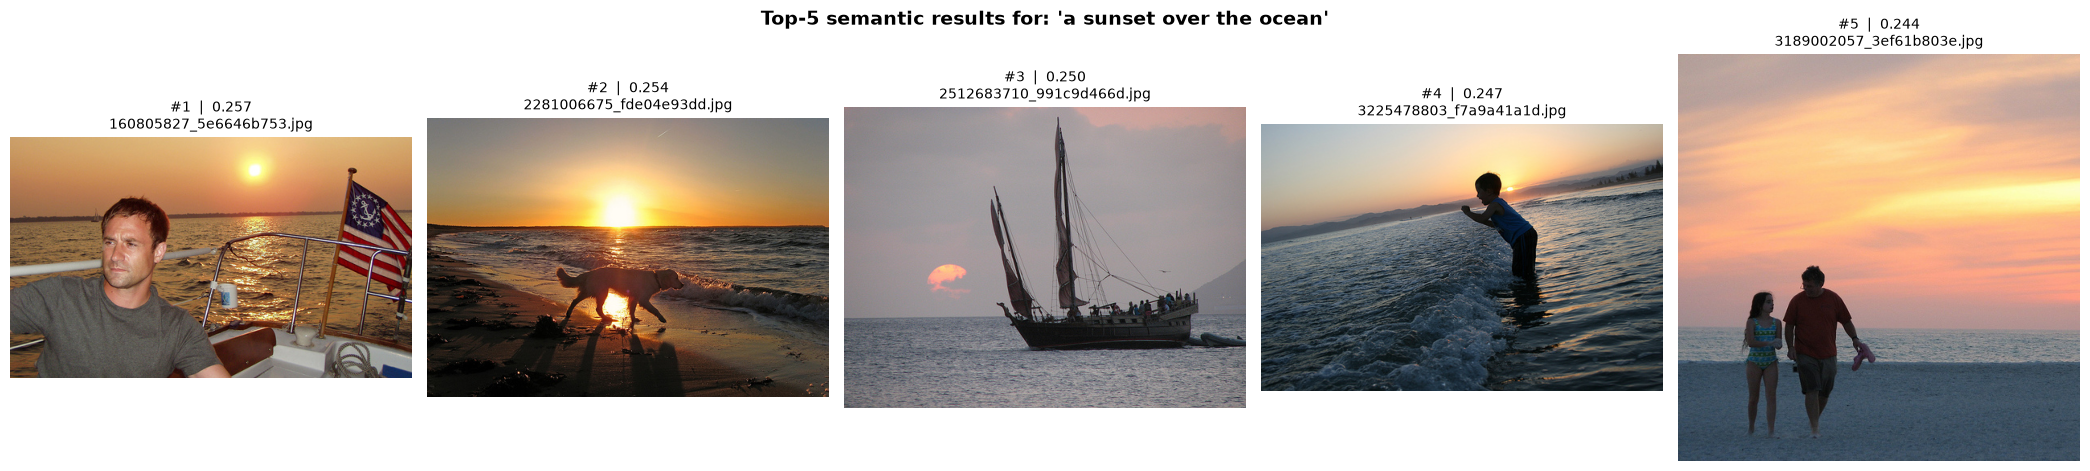

In [5]:
display_count = len(results)
fig, axes = plt.subplots(1, display_count, figsize=(4.2 * display_count, 4.8))
axes = np.atleast_1d(axes)

for axis, (path, score), rank in zip(axes, results, range(1, display_count + 1)):
    try:
        with Image.open(path) as image:
            axis.imshow(image.convert("RGB"))
        axis.set_title(f"#{rank}  |  {score:.3f}\n{Path(path).name}", fontsize=10)
    except OSError as error:
        axis.text(0.5, 0.5, f"Could not open image\n{error}", ha="center", va="center")
    axis.axis("off")

plt.suptitle(f"Top-{display_count} semantic results for: {QUERY!r}", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 4. Inspect relevance scores

The score chart makes the ranking transparent. Scores are relative to the current query and dataset rather than universal confidence percentages.


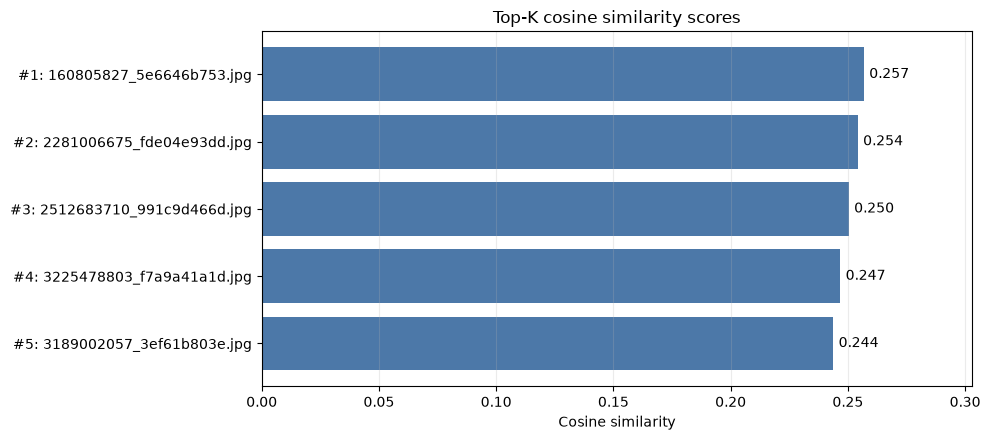

In [6]:
rank_labels = [f"#{rank}: {Path(path).name}" for rank, (path, _) in enumerate(results, start=1)]
result_scores = [score for _, score in results]

fig, axis = plt.subplots(figsize=(10, 4.5))
bars = axis.barh(rank_labels[::-1], result_scores[::-1], color="#4C78A8")
axis.bar_label(bars, fmt="%.3f", padding=4)
axis.set(title="Top-K cosine similarity scores", xlabel="Cosine similarity")
axis.set_xlim(0, max(result_scores) * 1.18 if result_scores else 1)
axis.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


## 5. Analyse the full score distribution

The Top-K images are only part of the picture. This histogram shows how every indexed image relates to the query. A distinct high-scoring tail suggests that the search has separated a small set of relevant candidates from the rest of the dataset.


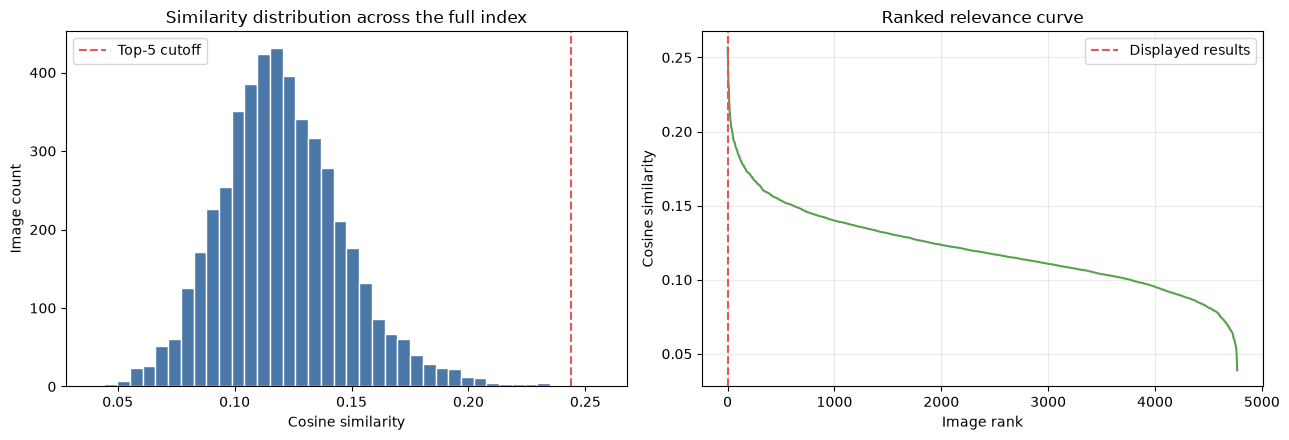

Index mean similarity: 0.121
Top result margin over rank 2: 0.003


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(similarity_scores, bins=min(40, len(similarity_scores)), color="#4C78A8", edgecolor="white")
axes[0].axvline(result_scores[-1], color="#E45756", linestyle="--", label=f"Top-{len(results)} cutoff")
axes[0].set(title="Similarity distribution across the full index", xlabel="Cosine similarity", ylabel="Image count")
axes[0].legend()

sorted_scores = np.sort(similarity_scores)[::-1]
rank_positions = np.arange(1, len(sorted_scores) + 1)
axes[1].plot(rank_positions, sorted_scores, color="#59A14F")
axes[1].axvline(len(results), color="#E45756", linestyle="--", label="Displayed results")
axes[1].set(title="Ranked relevance curve", xlabel="Image rank", ylabel="Cosine similarity")
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Index mean similarity: {similarity_scores.mean():.3f}")
print(f"Top result margin over rank 2: {(result_scores[0] - result_scores[1]):.3f}")


## 6. Compare several natural-language queries

A shared CLIP space should respond differently to different concepts. The heatmap compares a few example prompts against the same top images from the primary query. It is a compact way to see how changing language changes image relevance.


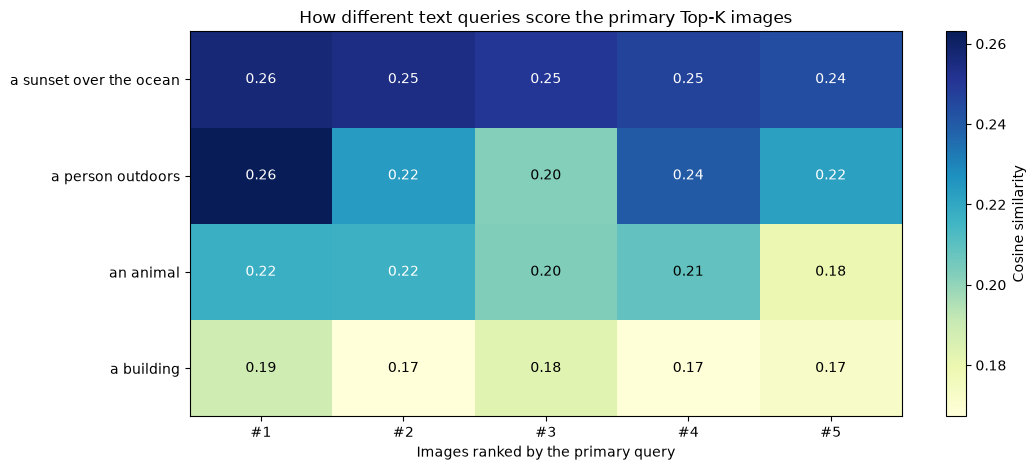

In [8]:
comparison_queries = [QUERY, "a person outdoors", "an animal", "a building"]
top_result_indices = [image_paths.index(path) for path, _ in results]
comparison_scores = []
for comparison_query in comparison_queries:
    comparison_embedding = embedder.generate_text_embedding(comparison_query)
    comparison_scores.append(cosine_similarity(comparison_embedding, image_embeddings)[top_result_indices])

fig, axis = plt.subplots(figsize=(11, 4.8))
heatmap = axis.imshow(comparison_scores, cmap="YlGnBu", aspect="auto")
axis.set_yticks(range(len(comparison_queries)), comparison_queries)
axis.set_xticks(range(len(results)), [f"#{rank}" for rank in range(1, len(results) + 1)])
axis.set(title="How different text queries score the primary Top-K images", xlabel="Images ranked by the primary query")
for row, score_row in enumerate(comparison_scores):
    for column, score in enumerate(score_row):
        color = "white" if score > np.mean(comparison_scores) else "black"
        axis.text(column, row, f"{score:.2f}", ha="center", va="center", color=color)
fig.colorbar(heatmap, ax=axis, label="Cosine similarity")
plt.tight_layout()
plt.show()


## Interpretation and next steps

- Cosine similarity is a ranking signal, not a probability. Judge retrieval quality by visually reviewing the Top-K grid.
- Broad queries can return varied images; adding descriptive details usually produces a sharper ranking.
- Change `QUERY`, rerun the text-embedding and retrieval sections, and compare the analysis charts to evaluate the effect of prompt wording.
- The same saved index and `top_k_search` function are reused by `main.py` and the Streamlit interface.
